# 7. Final evaluation

All numbers are out-of-fold: each patient is predicted by models, a meta-learner, blend weights and
thresholds that were fitted without that patient.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.figsize": (8, 4), "axes.spines.top": False, "axes.spines.right": False})

In [2]:
from workflow_ml.config import LABELS
from workflow_ml.train import fold_f1, report, run_experiment, save, summary

experiment = run_experiment()
results = report(experiment)
save(experiment, results)
overview = summary(experiment, results)
overview

scoring random_forest ...
scoring mlp ...
scoring gradient_boosting ...
scoring gru ...
stacking and evolving the blend ...


scope,all_patients,without_largest_patients,fold_mean,fold_std
model,,,,
random_forest,0.745,0.581,0.671,0.101
mlp,0.606,0.525,0.587,0.064
gradient_boosting,0.783,0.680,0.737,0.078
gru,0.684,0.561,0.634,0.071
stacking,0.779,0.679,0.738,0.075
ga_blend,0.789,0.681,0.742,0.076


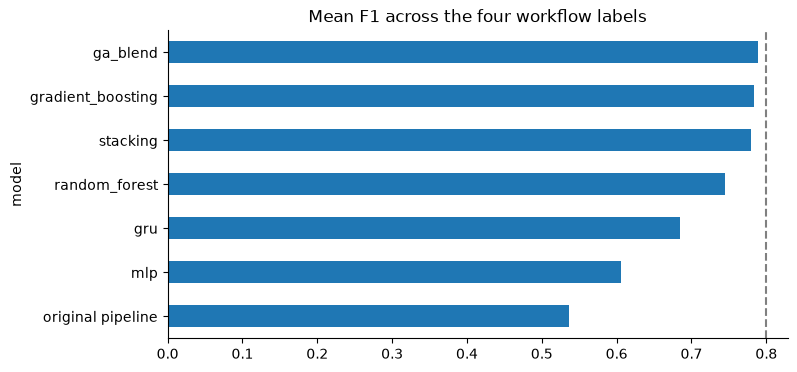

In [3]:
ORIGINAL_MEAN_F1 = 0.536  # best result reported in the original README (Random Forest, longitudinal)

mean_f1 = overview["all_patients"].copy()
mean_f1.loc["original pipeline"] = ORIGINAL_MEAN_F1
mean_f1.sort_values().plot.barh(title="Mean F1 across the four workflow labels")
plt.axvline(0.8, linestyle="--", color="grey");

## Final model per label

In [4]:
final = results[(results["model"] == "ga_blend") & (results["scope"] == "all_patients")].set_index("label")
final[["precision", "recall", "f1", "accuracy", "pr_auc", "roc_auc"]].round(3)

,precision,recall,f1,accuracy,pr_auc,roc_auc
label,,,,,,
medical_exam,0.630,0.784,0.699,0.883,0.753,0.933
lab_test,0.865,0.855,0.860,0.949,0.943,0.980
imaging,0.761,0.729,0.745,0.991,0.728,0.938
instrument_test,0.840,0.864,0.851,0.987,0.761,0.970


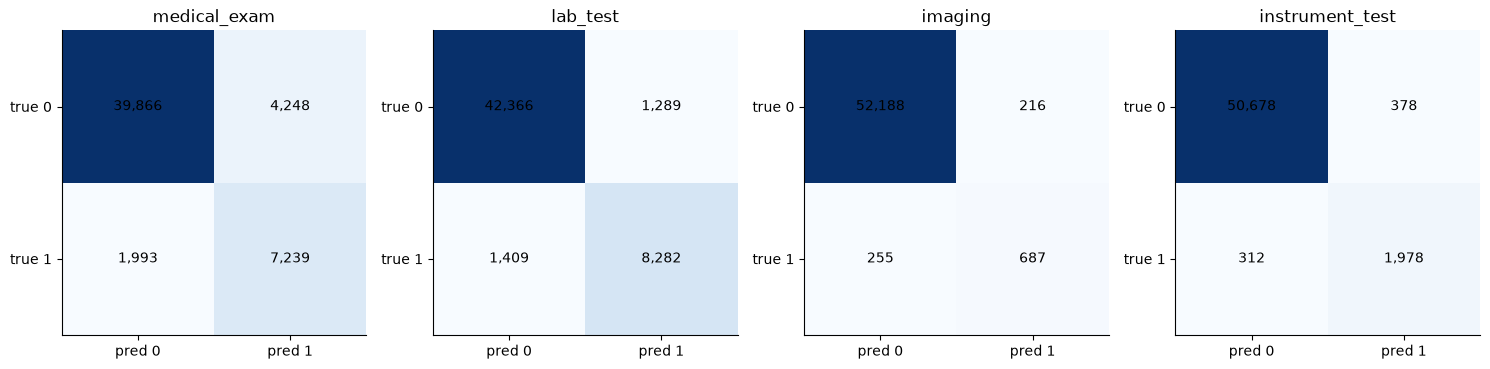

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
for label, ax in zip(LABELS, axes):
    row = final.loc[label]
    matrix = np.array([[row["tn"], row["fp"]], [row["fn"], row["tp"]]], dtype=int)
    ax.imshow(matrix, cmap="Blues")
    for (i, j), value in np.ndenumerate(matrix):
        ax.text(j, i, f"{value:,}", ha="center", va="center")
    ax.set(title=label, xticks=[0, 1], yticks=[0, 1], xticklabels=["pred 0", "pred 1"],
           yticklabels=["true 0", "true 1"])
plt.tight_layout()

## How stable is the result?

Three patients have 1,500–2,000 encounters each and hold most `instrument_test` positives, so the
score depends on which fold they land in. Two honest checks: the spread across folds, and the score
with those patients removed.

In [6]:
fold_f1(experiment).round(3)

,random_forest,mlp,gradient_boosting,gru,stacking,ga_blend
fold,,,,,,
0,0.602,0.483,0.631,0.593,0.643,0.642
1,0.712,0.602,0.755,0.682,0.756,0.758
2,0.744,0.615,0.816,0.734,0.811,0.821
3,0.769,0.654,0.799,0.589,0.802,0.802
4,0.530,0.582,0.686,0.571,0.678,0.687


In [7]:
results[results["model"] == "ga_blend"].pivot(index="label", columns="scope", values="f1").round(3)

scope,all_patients,without_largest_patients
label,,
imaging,0.745,0.752
instrument_test,0.851,0.561
lab_test,0.860,0.735
medical_exam,0.699,0.676
